In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Pandas (EDA) Tasks**

**Task 1**
Load dataset.

In [2]:
# read dataset.
df=pd.read_csv("D:/DA Project/Data set/netflix_titles.csv")
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

**Task 2**
Explore DataSet

In [3]:
# Explore DataSet
# datasets lines and colums
df.shape

(8807, 12)

In [4]:
# colums / null values / dataypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
# statistial summary of all colums
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8804,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,15-Aug,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,2,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [6]:
# colums datatype 
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Change data type

In [7]:
# Remove leading/trailing spaces, then convert text to datetime
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")

df["date_added"].dtype  # datetime64[ns] means it is now a proper date column

dtype('<M8[ns]')

In [8]:
print(df["date_added"].dtype)         # datetime64[ns]
print(df["date_added"].isna().sum())  # number of dates that failed to convert (NaT)
df["date_added"].head()

datetime64[ns]
10


0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[ns]

In [9]:
# Pull the digits out of the text: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)

df[["duration", "duration_num"]].head()  # check original vs numeric side by side

,duration,duration_num
0,90 min,90.0
1,2 Seasons,2.0
2,1 Season,1.0
3,1 Season,1.0
4,2 Seasons,2.0


In [10]:
movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]

print("Average movie duration (min):", round(movies["duration_num"].mean(), 1))
print("Average seasons per TV show:", round(shows["duration_num"].mean(), 1))

Average movie duration (min): 99.6
Average seasons per TV show: 1.8


In [11]:
df.nunique()

show_id         8807
type               2
title           8804
director        4528
cast            7692
country          748
date_added      1714
release_year      74
rating            17
duration         220
listed_in        514
description     8775
duration_num     210
dtype: int64

**Task 3**
Handle missing values. 

In [12]:
# check missing values : 
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
duration_num       3
dtype: int64

In [13]:
# A few rows have the duration (e.g. "74 min") stored in the 'rating' column by mistake
mask = df["rating"].astype(str).str.contains("min", na=False)  # find those rows
print("Misplaced rows:", mask.sum())

df.loc[mask, "duration"] = df.loc[mask, "rating"]  # move the value to the correct column
df.loc[mask, "rating"] = np.nan                    # clear rating so it gets filled in the next step

Misplaced rows: 3


In [14]:
# 3 rows have the duration (e.g. "74 min") stored in the 'rating' column by mistake
mask = df["rating"].astype(str).str.contains("min", na=False)  # find those rows
print("Misplaced rows:", mask.sum())

df.loc[mask, "duration"] = df.loc[mask, "rating"]  # move the value to the correct column
df.loc[mask, "rating"] = np.nan                    # clear rating; it gets filled in the next cell

Misplaced rows: 0


In [15]:
# director, cast, country: too many missing to drop, so label them "Unknown"
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")

# rating: categorical column, so fill with the most frequent value (mode)
df["rating"] = df["rating"].fillna(df["rating"].mode()[0])

# date_added: convert to datetime only if it is still text (safe to re-run)
if df["date_added"].dtype == "object":
    df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")

# date_added: drop the rows where the date is missing
df = df.dropna(subset=["date_added"]).reset_index(drop=True)

print(df["date_added"].dtype)  # should show datetime64[ns]

datetime64[ns]


In [16]:
# Rebuild the numeric duration now that the 3 misplaced values are fixed
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)

**Task 4**
Remove Duplicates 

In [17]:
# Check for duplicates
# check duplicate value
duplicate_count=df.duplicated().sum()
duplicate_count

np.int64(0)

In [18]:
# Rows that are completely identical across every column
print("Exact duplicates:", df.duplicated().sum())

# Rows with the same title, type and release year (same show listed twice with different IDs)
print("Duplicates on title+type+year:",
      df.duplicated(subset=["title", "type", "release_year"]).sum())

# show_id should be unique for every row
print("Duplicate show_id:", df["show_id"].duplicated().sum())

Exact duplicates: 0
Duplicates on title+type+year: 3
Duplicate show_id: 0


In [19]:
# Remove duplicates
print("Shape before:", df.shape)

# Drop fully identical rows, keeping the first occurrence
df = df.drop_duplicates()

# Drop rows that repeat the same title, type and release year
df = df.drop_duplicates(subset=["title", "type", "release_year"], keep="first")

df = df.reset_index(drop=True)  # rebuild a clean 0..n index after dropping rows

print("Shape after:", df.shape)

Shape before: (8797, 13)
Shape after: (8794, 13)


In [20]:
# Helper columns (safe to run again)
df["year_added"] = df["date_added"].dt.year
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)

# Movies and TV shows separately
movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]

# One row per genre
genres = df.assign(genre=df["listed_in"].str.split(",")).explode("genre")
genres["genre"] = genres["genre"].str.strip()

# One row per country
countries = df.assign(country=df["country"].str.split(",")).explode("country")
countries["country"] = countries["country"].str.strip()
countries = countries[~countries["country"].isin(["Unknown", ""])]

# One row per director
directors = df.assign(director=df["director"].str.split(",")).explode("director")
directors["director"] = directors["director"].str.strip()
directors = directors[directors["director"] != "Unknown"]

# Counts used by the charts and insights
genre_counts = genres["genre"].value_counts()
country_counts = countries["country"].value_counts()
director_counts = directors["director"].value_counts()
rating_counts = df["rating"].value_counts()
by_year = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

print("Variables ready")

Variables ready


**Task 5**
Analyze release year trends. 

In [21]:
#Titles per release year, split by type
# Count Movies and TV Shows for each release year
by_year = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

# Add a total column
by_year["Total"] = by_year.sum(axis=1)

by_year.tail(10)  # last 10 years

type,Movie,TV Show,Total
release_year,,,
2012,173,63,236
2013,225,62,287
2014,264,88,352
2015,398,160,558
2016,658,243,901
2017,767,265,1032
2018,766,378,1144
2019,632,397,1029
2020,517,436,953


In [22]:
#Peak years
# Top 5 release years by number of titles
print(df["release_year"].value_counts().head(5))

# Range covered by the dataset
print("Oldest:", df["release_year"].min(), "| Newest:", df["release_year"].max())

release_year
2018    1144
2017    1032
2019    1029
2020     953
2016     901
Name: count, dtype: int64
Oldest: 1925 | Newest: 2021


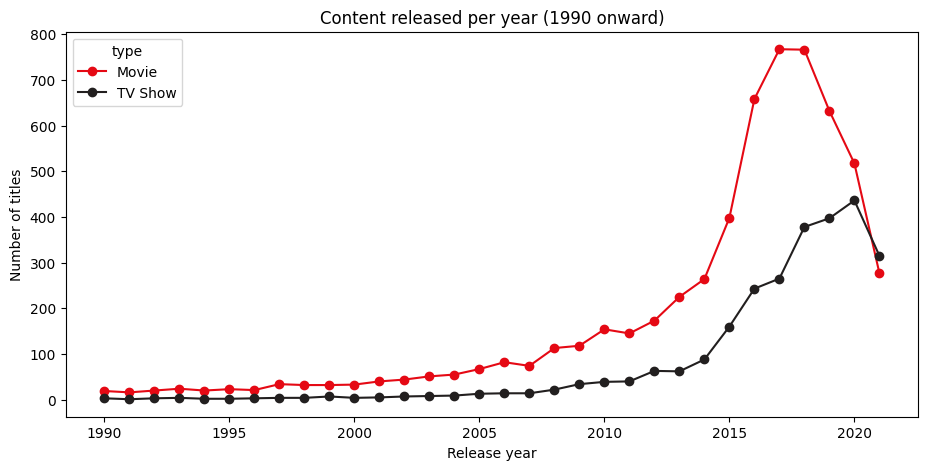

In [23]:
# Line chart of release trend
# The catalog is mostly recent, so plot from 1990 onward for a readable chart
by_year.loc[1990:, ["Movie", "TV Show"]].plot(
    figsize=(11, 5), marker="o", color=["#E50914", "#221F1F"])
plt.title("Content released per year (1990 onward)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.show()

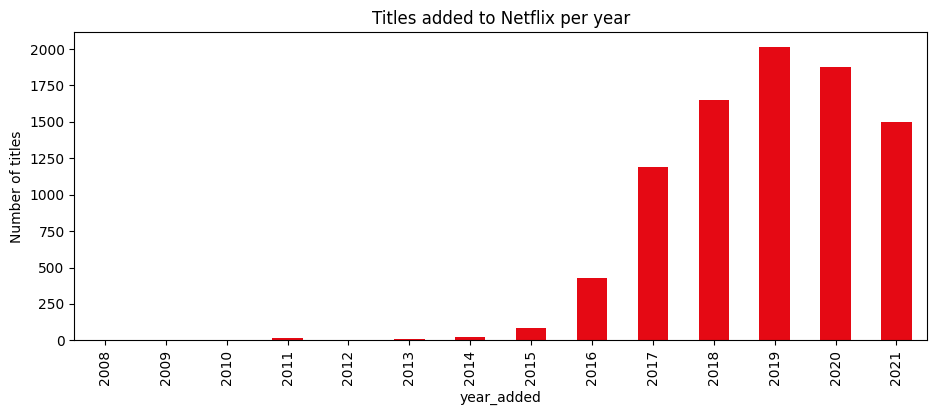

In [24]:
# Netflix addition trend (year added)
# Release year = when it was made. Year added = when Netflix put it on the platform.
df["year_added"] = df["date_added"].dt.year

added = df["year_added"].value_counts().sort_index()  # titles added per year
added.plot(kind="bar", figsize=(11, 4), color="#E50914",
           title="Titles added to Netflix per year")
plt.ylabel("Number of titles")
plt.show()

**Insight :-**
Netflix expanded its library quickly from 2016 to 2019, then became more selective, and it is shifting its focus from movies to TV shows. The 2021 numbers are low only because the data was collected before the year ended.

**Task 6**
Analyze genre distribution.

In [25]:
# Split the comma-separated genres so each genre gets its own row
genres = df.assign(genre=df["listed_in"].str.split(",")).explode("genre")
genres["genre"] = genres["genre"].str.strip()  # remove extra spaces

# Number of titles in each genre (a title with 3 genres is counted once in each)
genre_counts = genres["genre"].value_counts()

print("Total distinct genres:", genre_counts.shape[0])
genre_counts.head(10)  # top 10 genres

Total distinct genres: 42


genre
International Movies        2752
Dramas                      2425
Comedies                    1673
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

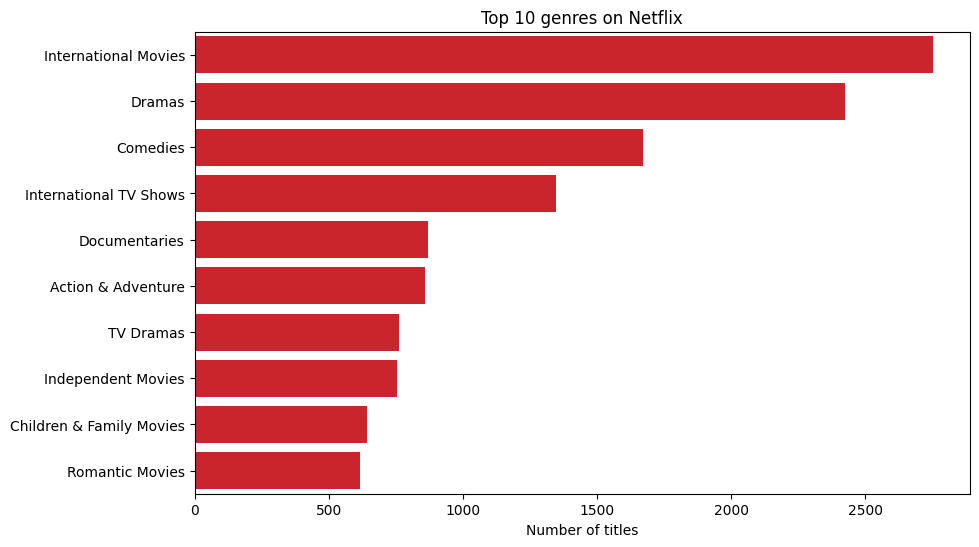

In [26]:
# Bar chart of the top 10 genres
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.head(10).values, y=genre_counts.head(10).index, color="#E50914")
plt.title("Top 10 genres on Netflix")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

In [27]:
# Top 10 genres inside each type
for t in ["Movie", "TV Show"]:
    print(t)
    print(genres[genres["type"] == t]["genre"].value_counts().head(10), "\n")

Movie
genre
International Movies        2752
Dramas                      2425
Comedies                    1673
Documentaries                869
Action & Adventure           859
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Thrillers                    576
Music & Musicals             375
Name: count, dtype: int64 

TV Show
genre
International TV Shows    1349
TV Dramas                  761
TV Comedies                574
Crime TV Shows             469
Kids' TV                   449
Docuseries                 394
Romantic TV Shows          370
Reality TV                 255
British TV Shows           252
Anime Series               175
Name: count, dtype: int64 



**Insight**

Netflix has 42 different genres, but a few genres dominate. International Movies is the biggest (2,752 titles, about 31% of all titles), followed by Dramas (2,427) and Comedies (1,674). Together, the top 5 genres make up about 47% of all genre tags, so the catalog is concentrated in a few categories. The popular genres are also different for each type: Movies lead with International Movies, Dramas and Comedies, while TV Shows lead with International TV Shows (1,350), TV Dramas (762) and TV Comedies (574). Niche genres like Romantic Movies (616) and Children & Family Movies (641) are much smaller. Overall, Netflix is strongest in international and drama content, which fits its goal of serving viewers around the world. Netflix could grow smaller genres like family content to reach more audiences.

 “The bar chart shows International Movies and Dramas lead by a big margin, and Netflix’s library is built around a few strong genres, so adding more in smaller genres is a growth opportunity.”

**Task 7**
Analyze ratings.

In [28]:
# Ratings count and percentage
# Number of titles for each rating
rating_counts = df["rating"].value_counts()
print(rating_counts)

# Share of each rating in %
print((df["rating"].value_counts(normalize=True) * 100).round(1))

rating
TV-MA       3212
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64
rating
TV-MA       36.5
TV-14       24.5
TV-PG        9.8
R            9.1
PG-13        5.6
TV-Y7        3.8
TV-Y         3.5
PG           3.3
TV-G         2.5
NR           0.9
G            0.5
TV-Y7-FV     0.1
NC-17        0.0
UR           0.0
Name: proportion, dtype: float64


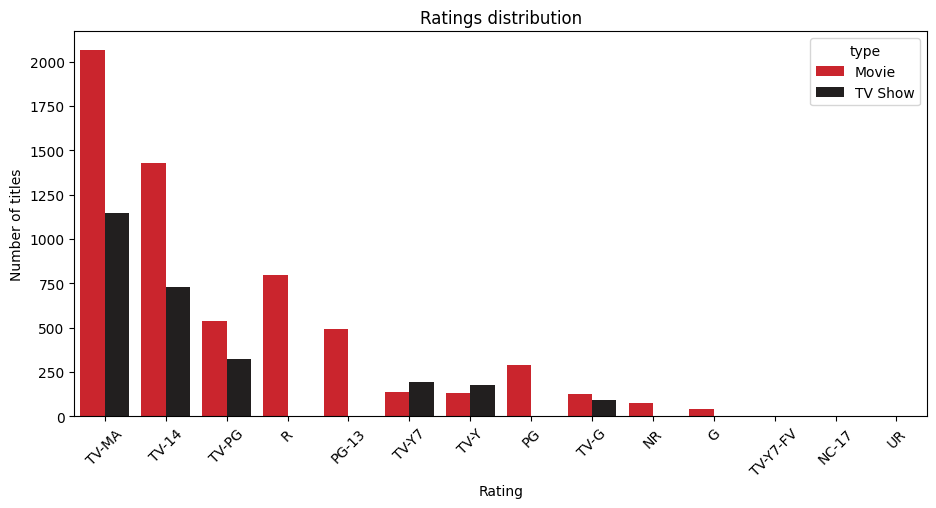

In [29]:
# Ratings chart (Movie vs TV Show)
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="rating", hue="type", order=rating_counts.index,
              palette=["#E50914", "#221F1F"])  # separate colors for Movie and TV Show
plt.xticks(rotation=45)                         # rotate labels so they don't overlap
plt.title("Ratings distribution")
plt.xlabel("Rating")
plt.ylabel("Number of titles")
plt.show()

**Insight**

Netflix focuses mainly on mature and teen audiences, and family and kids’ content is the smallest segment. This is a growth opportunity: adding more family-friendly shows would help Netflix reach households with children.

“The bar chart shows TV-MA and TV-14 dominate the catalog, so Netflix is built around adult and teen viewers, while kids’ content is only about 10%, which is a gap I would recommend filling.”

**Task 8**
Analyze duration.

In [30]:
# Mean, median, spread and quartiles of movie length in minutes
print(movies["duration_num"].describe().round(1))

count    6129.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0
Name: duration_num, dtype: float64


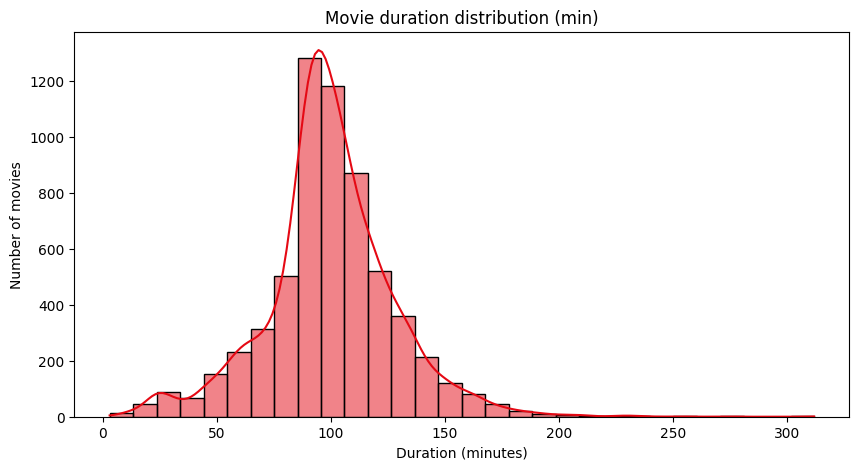

In [31]:
# Histogram of movie duration
plt.figure(figsize=(10, 5))
sns.histplot(movies["duration_num"], bins=30, kde=True, color="#E50914")  # kde adds the smooth curve
plt.title("Movie duration distribution (min)")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of movies")
plt.show()

In [32]:
# TV shows are in seasons, so analyze them separately
print(shows["duration_num"].value_counts().sort_index())
print("Average seasons:", round(shows["duration_num"].mean(), 1))
print("Shows with only 1 season (%):", round((shows["duration_num"] == 1).mean() * 100, 1))

duration_num
1.0     1792
2.0      421
3.0      198
4.0       94
5.0       64
6.0       33
7.0       23
8.0       17
9.0        9
10.0       6
11.0       1
12.0       2
13.0       2
15.0       2
17.0       1
Name: count, dtype: int64
Average seasons: 1.8
Shows with only 1 season (%): 67.2


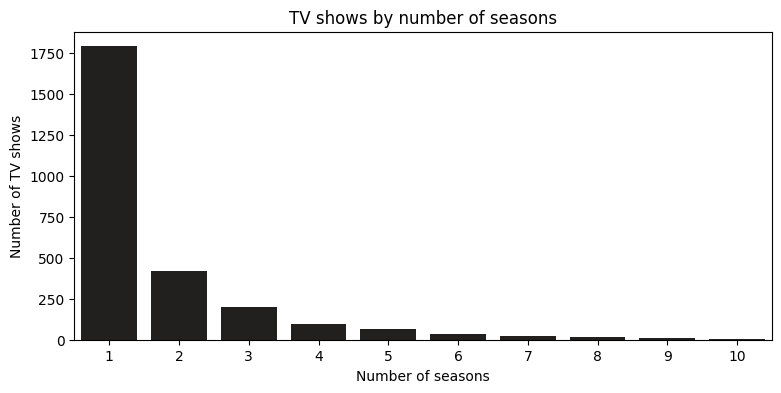

In [33]:
# Bar chart of tv shows seasons
# Number of TV shows for each season count (top 10 only; very long-running shows are rare)
season_counts = shows["duration_num"].value_counts().sort_index().head(10)

plt.figure(figsize=(9, 4))
sns.barplot(x=season_counts.index.astype(int), y=season_counts.values, color="#221F1F")
plt.title("TV shows by number of seasons")
plt.xlabel("Number of seasons")
plt.ylabel("Number of TV shows")
plt.show()

**Insight**

This histogram shows movie length in minutes. Most movies are around 100 minutes, and half are between 87 and 114. A few very long titles, like Black Mirror: Bandersnatch at 312 minutes, make the tail on the right. TV shows are measured in seasons, not minutes, and the average is only 1.8, with about 67% having just one season. So Netflix mostly offers content that is easy to finish.

**Task 9** 
Analyze country-wise content. 

In [34]:
# Titles per country
# Number of titles per country (a co-produced title counts once for each country)
country_counts = countries["country"].value_counts()

print("Total countries:", country_counts.shape[0])
country_counts.head(10)  # top 10 countries

Total countries: 122


country
United States     3683
India             1045
United Kingdom     805
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

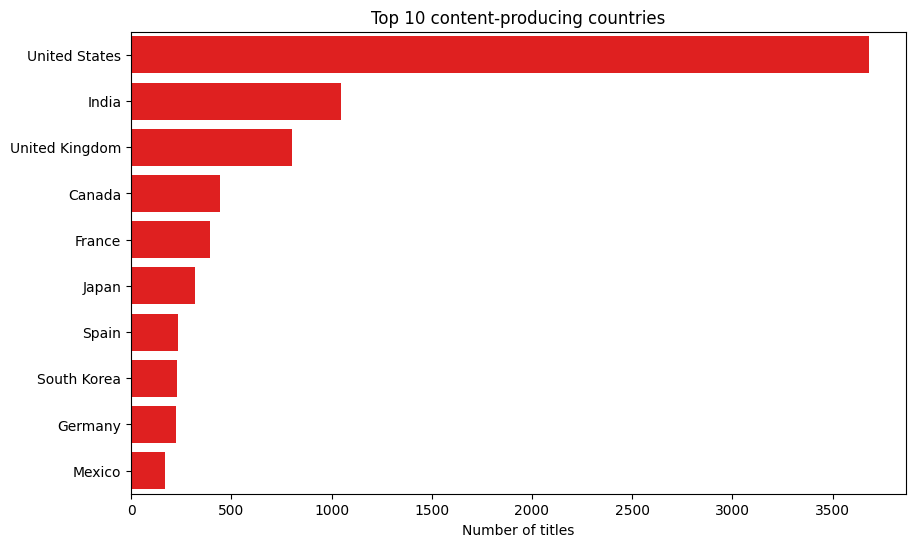

In [35]:
# Bar chart of top countries
plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.head(10).values, y=country_counts.head(10).index, color="red")
plt.title("Top 10 content-producing countries")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

**Insight**
  
The United States produces by far the most content with 3,684 titles, which is about 46% of titles with a known country. India is second (1,046) and the United Kingdom is third (805), followed by Canada (445), France (393) and Japan (317). The top 3 countries together are involved in about 69% of titles, so Netflix’s catalog is concentrated in a few countries, even though 122 countries appear in the data. The type of content also differs by country: India is mostly movies (962 movies vs 84 TV shows), while South Korea (74% TV shows) and Japan (62% TV shows) are strongest in series. About 38 countries have only a single title, so many regions are barely represented. Overall, Netflix relies heavily on the US, with India and the UK as strong secondary markets, and there is room to grow content from smaller regions.

“The bar chart shows the US leads by a big margin, India and the UK follow, and a handful of countries make up most of the catalog. Korea and Japan stand out for TV shows, so Netflix could invest more in international series to reach new audiences.”

**Task 10**
Analyze director contributions. 

In [36]:
# Titles per director
# Split the comma-separated directors so each director gets its own row
directors = df.assign(director=df["director"].fillna("Unknown").str.split(",")).explode("director")
directors["director"] = directors["director"].str.strip()  # remove extra spaces
directors = directors[directors["director"] != "Unknown"]  # drop titles with no director

# Number of titles per director (a title with 2 directors counts once for each)
director_counts = directors["director"].value_counts()

print("Total distinct directors:", director_counts.shape[0])
director_counts.head(10)  # top 10 directors

Total distinct directors: 4993


director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Marcus Raboy           16
Suhas Kadav            16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Name: count, dtype: int64

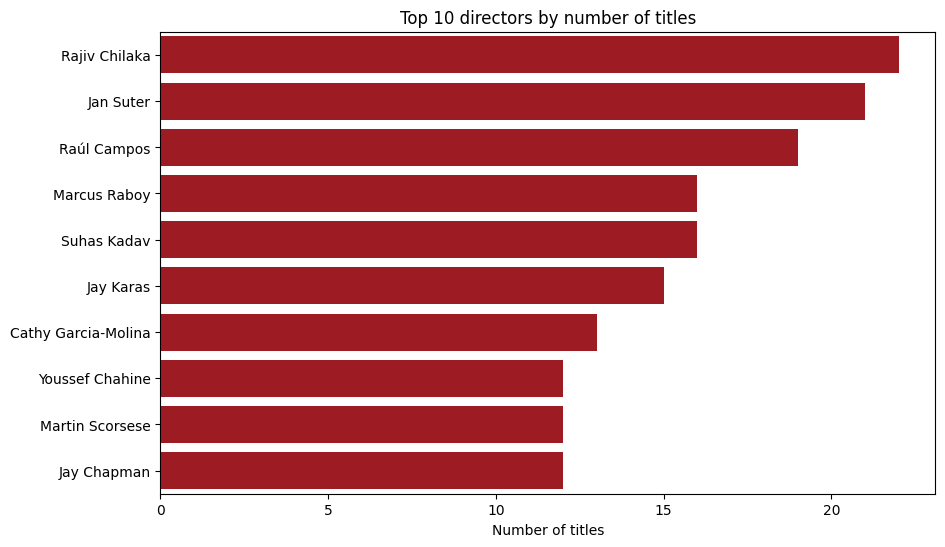

In [37]:
# Bar chart of top directors
plt.figure(figsize=(10, 6))
sns.barplot(x=director_counts.head(10).values, y=director_counts.head(10).index, color="#B20710")
plt.title("Top 10 directors by number of titles")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

**Insight**

Chart (Top 10 directors): Director contributions are spread very thin. The top director, Rajiv Chilaka, has only 22 titles, followed by Jan Suter (21), Raúl Campos (19), Suhas Kadav and Marcus Raboy (16 each). The top 10 directors together account for only about 2% of all director credits, and about 80% of the roughly 5,000 directors appear on just one title. Only about 119 directors have 5 or more titles. Almost all top directors made movies (22 of Rajiv Chilaka’s 22 are movies), and many are known for stand-up comedy specials (Jan Suter, Raúl Campos, Marcus Raboy, Jay Karas) or kids’ animation (Rajiv Chilaka). Overall, Netflix’s catalog is not built around a few star directors. It works with a huge number of different creators, and a small group of specialists supply repeat content in niche formats like stand-up and children’s animation.

“The bar chart shows even the top director has only 22 titles, so no single director dominates, and Netflix relies on a wide pool of creators. Repeat directors cluster in stand-up comedy and kids’ content.”

**Task 11**
Generate business insights. 

In [38]:
# key insights
total = len(df)                                                         # total titles
movie_share = (df["type"] == "Movie").mean() * 100                      # share of movies in %
mature_share = df["rating"].isin(["TV-MA", "R", "NC-17"]).mean() * 100  # share of adult-rated titles in %
known_country = (df["country"] != "Unknown").sum()                      # titles with a known country
top3_share = country_counts.head(3).sum() / known_country * 100         # share of the top 3 countries
one_season = (shows["duration_num"] == 1).mean() * 100                  # TV shows with only 1 season in %

print(f"1. Catalog size: {total:,} titles, {len(movies):,} movies ({movie_share:.1f}%) and {len(shows):,} TV shows ({100 - movie_share:.1f}%).")
print(f"2. Release peak: {df['release_year'].value_counts().idxmax()} | Most titles added: {df['year_added'].value_counts().idxmax()}")
print(f"3. Top genre: {genre_counts.index[0]} ({genre_counts.iloc[0]:,} titles); distinct genres: {genre_counts.shape[0]}")
print(f"4. Top country: {country_counts.index[0]} ({country_counts.iloc[0]:,} titles); top 3 countries cover {top3_share:.0f}% of titles with a known country")
print(f"5. Mature content (TV-MA/R/NC-17): {mature_share:.1f}%")
print(f"6. Average movie: {movies['duration_num'].mean():.0f} min | Average TV show: {shows['duration_num'].mean():.1f} seasons ({one_season:.0f}% have 1 season)")
print(f"7. Top director: {director_counts.index[0]} ({director_counts.iloc[0]} titles); directors with only 1 title: {(director_counts == 1).mean() * 100:.0f}%")

1. Catalog size: 8,794 titles, 6,129 movies (69.7%) and 2,665 TV shows (30.3%).
2. Release peak: 2018 | Most titles added: 2019
3. Top genre: International Movies (2,752 titles); distinct genres: 42
4. Top country: United States (3,683 titles); top 3 countries cover 69% of titles with a known country
5. Mature content (TV-MA/R/NC-17): 45.6%
6. Average movie: 100 min | Average TV show: 1.8 seasons (67% have 1 season)
7. Top director: Rajiv Chilaka (22 titles); directors with only 1 title: 80%


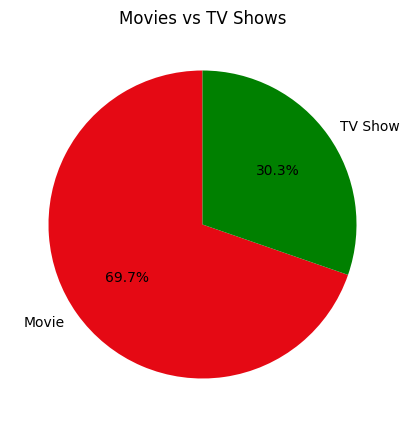

In [39]:
# Optional: one summary chart of the catalog mix (Movies vs TV Shows)
type_counts = df["type"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%",
        colors=["#E50914", "green"], startangle=90)
plt.title("Movies vs TV Shows")
plt.show()

**Data Visualization Tasks**

In [40]:
# Counts used by several charts
genre_counts = genres["genre"].value_counts()          # titles per genre
country_counts = countries["country"].value_counts()   # titles per country
director_counts = directors["director"].value_counts() # titles per director
rating_counts = df["rating"].value_counts()            # titles per rating
by_year = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)  # releases per year

**Task 1**
Release Year Line Chart 

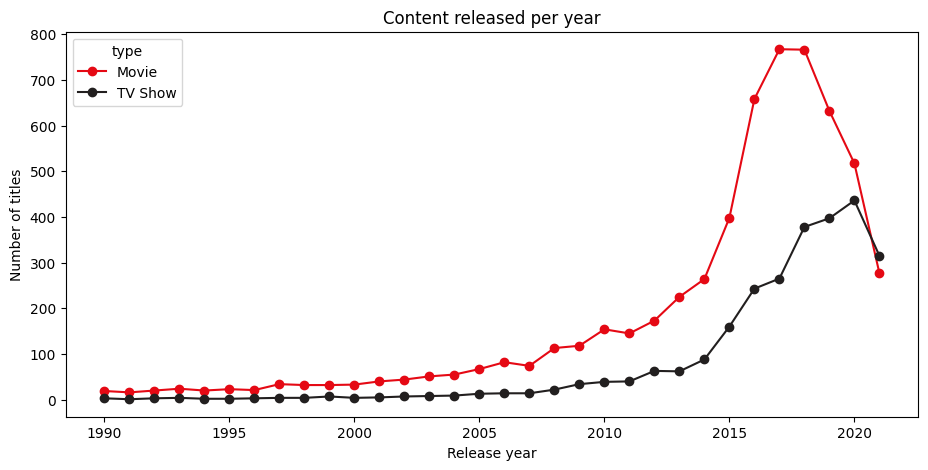

In [41]:
by_year.loc[1990:].plot(figsize=(11, 5), marker="o", color=["#E50914", "#221F1F"])  # 1990 onward is easier to read
plt.title("Content released per year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.show()

**Insight**

Netflix releases grew fast from 2015 and peaked in 2018 (about 1,146 titles). After that, movie releases fell while TV show releases kept growing, and in 2021 TV shows overtook movies (315 vs 277). The 2021 numbers are partial because the data was collected during that year.

**Task 2**
Genre Count Plot 

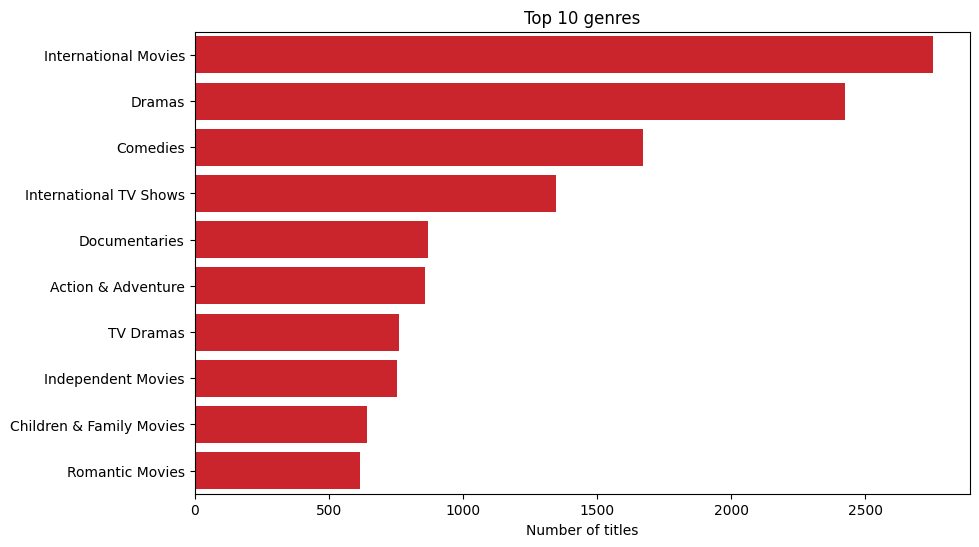

In [42]:
top_genres = genre_counts.head(10).index  # 10 most common genres
plt.figure(figsize=(10, 6))
sns.countplot(data=genres[genres["genre"].isin(top_genres)], y="genre",
              order=top_genres, color="#E50914")  # countplot counts the rows for each genre
plt.title("Top 10 genres")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

**Insight**

International Movies (2,752 titles), Dramas (2,427) and Comedies (1,674) are the biggest genres. Netflix’s catalog is strongest in international and drama content.

**Task 3**
Country-wise Bar Chart

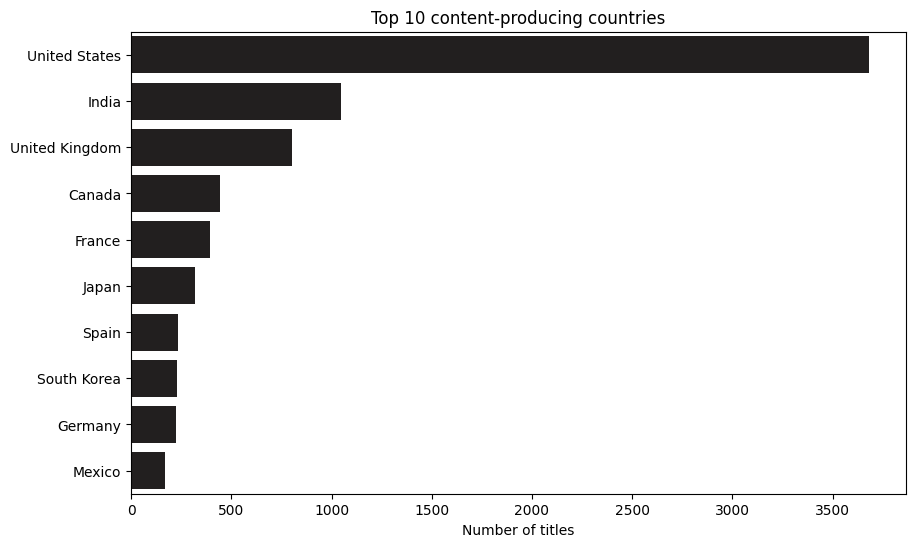

In [43]:
plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.head(10).values, y=country_counts.head(10).index, color="#221F1F")
plt.title("Top 10 content-producing countries")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

**Insight**

The United States leads by far with 3,684 titles, followed by India (1,046) and the United Kingdom (805). These three countries cover about 69% of titles with a known country.

**Task 4**
Movie vs TV Show Pie Chart

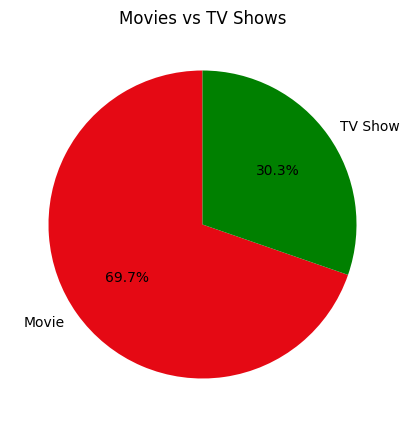

In [44]:
type_counts = df["type"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%",  # autopct prints the % on each slice
        colors=["#E50914", "green"], startangle=90)
plt.title("Movies vs TV Shows")
plt.show()

**Insight**

About 70% of the catalog is movies and about 30% is TV shows. Movies still dominate, though the first chart shows TV shows are catching up.

**Task 5**
Ratings Distribution

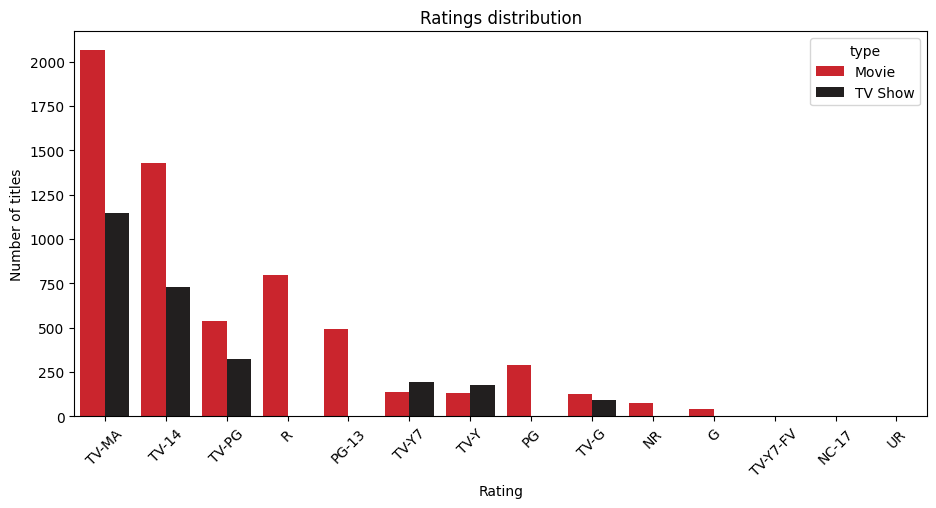

In [45]:
# 5. Ratings Distribution
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="rating", hue="type", order=rating_counts.index,
              palette=["#E50914", "#221F1F"])
plt.xticks(rotation=45)
plt.title("Ratings distribution")
plt.xlabel("Rating")
plt.ylabel("Number of titles")
plt.show()

**Insight**

TV-MA (3,212 titles) and TV-14 (2,157) are the most common ratings. Netflix’s content is mainly for adults and teens, and kids’ content is only about 10%.

**Task 6**
Duration Histogram

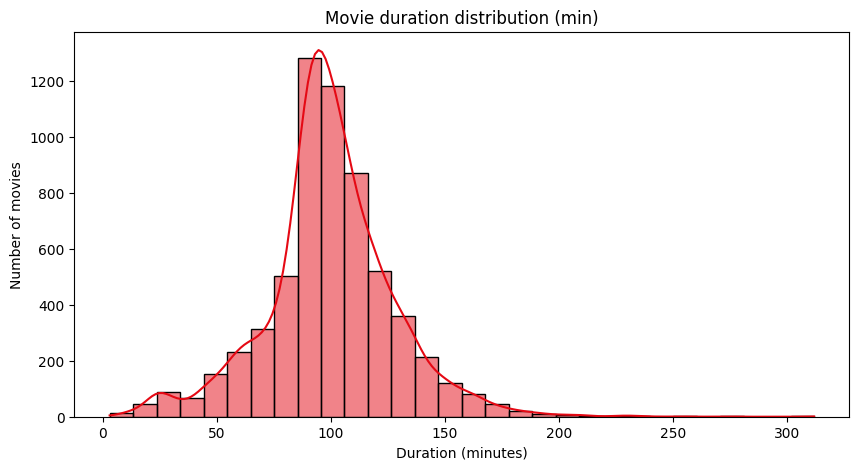

In [46]:
plt.figure(figsize=(10, 5))
sns.histplot(movies["duration_num"], bins=30, kde=True, color="#E50914")  # kde adds the smooth curve
plt.title("Movie duration distribution (min)")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of movies")
plt.show()

**Insight**

Most movies are around 100 minutes long, and half of all movies fall between 87 and 114 minutes. A few very long titles, like Black Mirror: Bandersnatch (312 minutes), form the small tail on the right.

**Task 7**
Top Directors Bar Chart

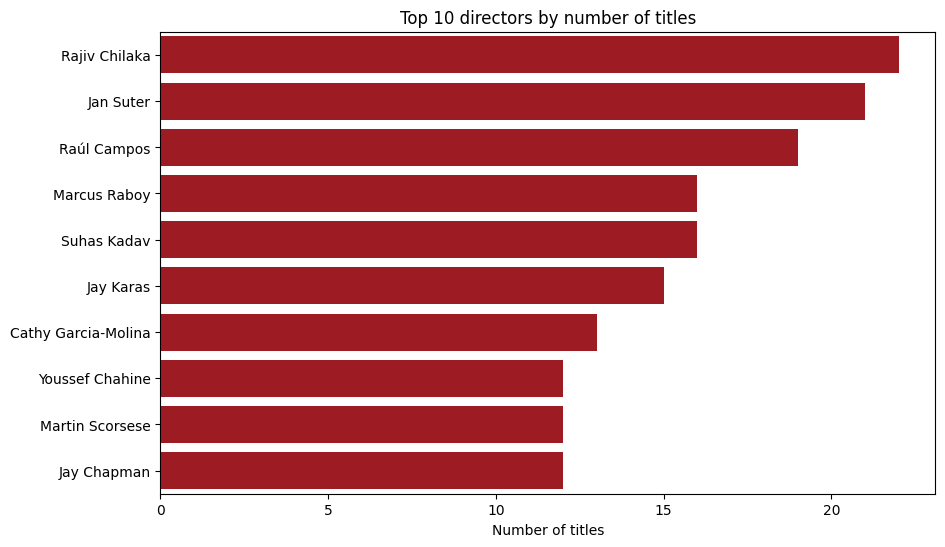

In [47]:
plt.figure(figsize=(10, 6))
sns.barplot(x=director_counts.head(10).values, y=director_counts.head(10).index, color="#B20710")
plt.title("Top 10 directors by number of titles")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.show()

**Insight**

The top director, Rajiv Chilaka, has only 22 titles. No single director dominates, so Netflix works with a very wide pool of creators.

**Task 8**
Box Plot

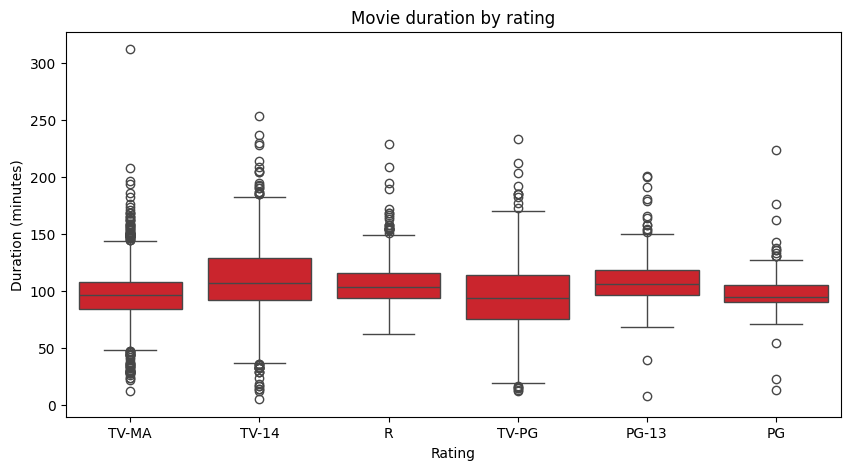

In [48]:
top_ratings = movies["rating"].value_counts().head(6).index  # 6 most common movie ratings
plt.figure(figsize=(10, 5))
sns.boxplot(data=movies[movies["rating"].isin(top_ratings)], x="rating", y="duration_num",
            order=top_ratings, color="#E50914")
plt.title("Movie duration by rating")
plt.xlabel("Rating")
plt.ylabel("Duration (minutes)")
plt.show()

**Insight**

Movie length is similar across ratings, with medians between about 94 and 107 minutes. The dots above the boxes are outliers, which are very long movies.

**Task 9**
Correlation Heatmap

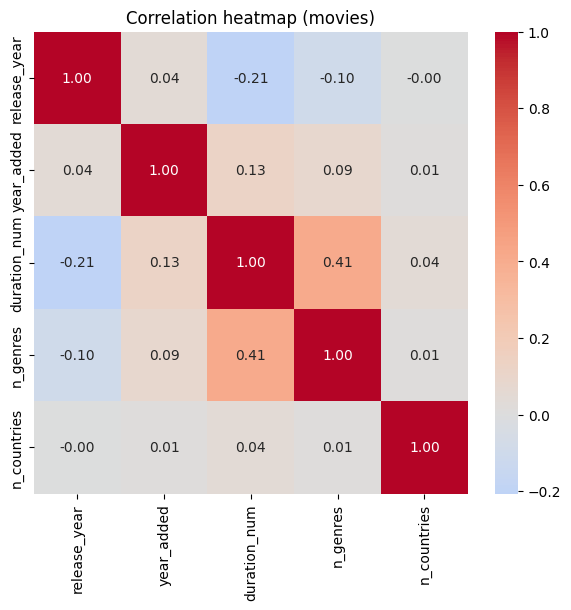

In [49]:
# Create numeric columns that don't exist yet
df["n_genres"] = df["listed_in"].str.split(",").str.len()                                  # genres per title
df["n_countries"] = df["country"].replace("Unknown", np.nan).str.split(",").str.len()      # countries per title
movies = df[df["type"] == "Movie"]  # refresh so movies includes the new columns

num_cols = ["release_year", "year_added", "duration_num", "n_genres", "n_countries"]
plt.figure(figsize=(7, 6))
sns.heatmap(movies[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)  # annot prints the values
plt.title("Correlation heatmap (movies)")
plt.show()

**Insight**

Relationships between the numeric columns are weak. The strongest is movie duration with the number of genres (about 0.41), and newer movies are slightly shorter (release year and duration, about -0.21). Most other pairs are close to 0, which means no real connection.

**Task 10**
Pair Plot

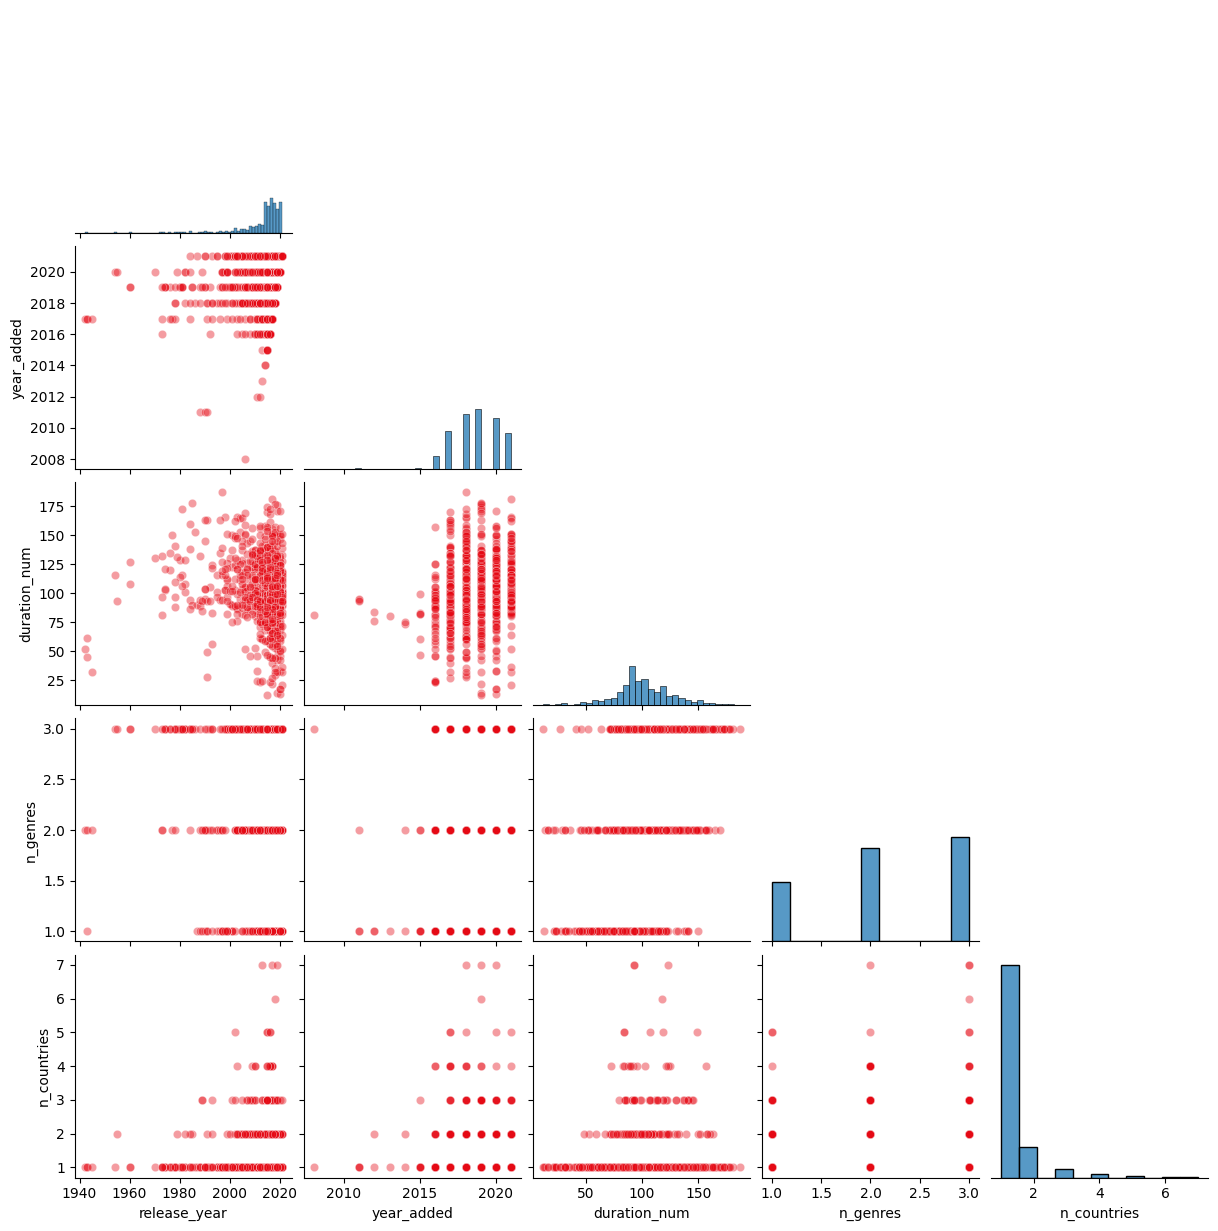

In [50]:
# A sample keeps the plot fast; corner=True hides the duplicate upper half
sns.pairplot(movies[num_cols].dropna().sample(1000, random_state=1), corner=True,
             plot_kws={"alpha": 0.4, "color": "#E50914"})
plt.show()

**Insight**

The scatter plots show the same thing as the heatmap: no strong patterns between the numeric columns, so one column cannot predict another here.

**Save Cleaned data**

In [58]:
# Save the cleaned data : 
# Save the cleaned dataset as a new CSV file
df.to_csv("netflix_clean.csv", index=False)

# checked the saved file : 
# Load the saved file again to confirm it was saved correctly
check_df = pd.read_csv("netflix_clean.csv")
print(check_df.shape)
check_df.head()

(8794, 16)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_num,year_added,n_genres,n_countries
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,2021,1,1.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,2021,3,1.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,2021,3,NaN
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,2021,2,NaN
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,2021,3,1.0


Find Path saved data 

In [52]:
import os

path = os.path.abspath("netflix_clean.csv")  # full path of the saved file
print("Full path:", path)
print("File exists:", os.path.exists(path))   # True means it was saved

Full path: C:\Users\Gautam\Documents\Project\netflix_clean.csv
File exists: False


**Connection SQL**

In [54]:
pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\Gautam\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [55]:
# Connect Jupyter sql workbench
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
import getpass

user = "root"                                  # your MySQL username (same as in Workbench)
password = quote_plus(getpass.getpass("MySQL password: "))  # asks for the password; quote_plus handles special characters like @
host = "localhost"
port = 3306
database = "netflix_db"

engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}")

# Test the connection
with engine.connect() as conn:
    print(conn.execute(text("SELECT DATABASE()")).fetchone())  # should print ('netflix_db',)

MySQL password:  ········


('netflix_db',)


In [56]:
# Send only the original columns; rename 'cast' to avoid a clash with the SQL CAST function
sql_df = df[["show_id", "type", "title", "director", "cast", "country", "date_added",
             "release_year", "rating", "duration", "listed_in", "description"]].rename(columns={"cast": "cast_members"})

# Create (or replace) the table netflix_titles in netflix_db
sql_df.to_sql("netflix_titles", engine, if_exists="replace", index=False, chunksize=1000)

print("Rows sent:", len(sql_df))  # should print 8797

Rows sent: 8794


In [58]:

pd.read_sql("SELECT COUNT(*) AS total_rows FROM netflix_titles", engine)  # should show 8797

,total_rows
0,8794
